# スタイル類似局面（DTW）予測による個別株スコア

野村「BPN スタイル配分戦略の改良方針」（2022/10）の DTW を、インド株の core スタイルに移植して検証する。
野村は日本のスタイル指数（S−L、V−G）の直近 3 か月の日次チャートに最も似た過去 3 局面を探し、その翌 3 か月リターンの平均を
期待リターンにしていた。ここではスタイルの予測を個別株スコアに変換し、既存の規約で評価する。

**手順**（定式化と符号表は `README.md`、生成は `scripts/build_style_dtw.py`）

1. core ファクターを符号調整してスタイルスコア $S_{i,k,t}$ を作る（8 スタイル + サイズ）
2. 月末のスタイルスコアで Q5 / Q1 を固定し、翌月の日次 Q5−Q1（等ウェイト）を日次スタイルリターンとする
3. 直近 63 営業日の累積リターンの推移を過去と DTW で照合し、近傍 3 個の翌 21 営業日リターン平均を予測 $\hat\mu_{k,t}$ とする
4. $\alpha_{i,t} = \mathrm{blom}\big(\sum_k (\hat\mu_{k,t}/\hat\sigma_{k,t}) S_{i,k,t}\big)$ を個別株スコアとする

**定式化からの変更点**

- 2007 年以前はユニバースが 15〜52 銘柄しかないため、スタイルリターンは 2008-02 から。評価は照合用の過去データを 3 年ためた 2011-01 から
- 照合候補はクエリの窓と重ならない過去（終端が 63 営業日以上前）に限る。直前の窓はほぼ自分自身と一致し、予測が「先月のリターン」になってしまうため

**規約**: Q5 = スコア最上位。評価は Q5（等ウェイトの BM 超過、BM = MSCI India）→ IC（Spearman）→ Q5−Q1 の順。
リターンは `drtn`（配当込み）と `srtn`（固有）。税・コストは入れていない。参考に既存の合成スコア `comp_ew` も並べる。

In [1]:
import sys
import warnings
from pathlib import Path

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../../scripts").resolve()))
from build_style_dtw import HORIZON, STYLE_MEMBERS, WINDOW

from alphaeval import (
    InputStore,
    compute_alpha_report,
    plot_cumulative,
    summary_table,
)

warnings.simplefilter("ignore", RuntimeWarning)
pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
OUT = Path("output")
SCORES = [
    "sdtw",
    "sdtw_z",
    "sdtw_sign",
    "sdtw_pos",
    "sknn_euc",
    "base_ew",
    "base_hist",
    "base_mom12",
    "base_mom3",
]
REFERENCE = {"comp_ew": "composite/comp_ew"}
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
RETURN_KINDS = {"drtn": "rtn", "srtn": "srtn"}
START, END = 201101, 202606
N_QUANTILES = 5
CW_MAX_WEIGHT = 0.05
BURN_IN = 1  # 初月（回転率 100%）だけ落とす。税を入れないので長いバーンインは不要

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
bm = store.benchmark(BENCHMARK, START, END)
paths = {**{n: f"style_dtw/{n}" for n in SCORES}, **REFERENCE}
scores = {
    n: store.alpha(p, START, END)
    .reindex(index=univ.index, columns=univ.columns)
    .where(univ.notna())
    for n, p in paths.items()
}

g = pd.read_csv(OUT / "style_daily_returns.csv", index_col=0, parse_dates=True)
fc = pd.read_csv(OUT / "style_forecasts.csv", parse_dates=["month"])
nbr = pd.read_csv(OUT / "neighbors.csv", parse_dates=["month", "neighbor_end"])
STYLES = list(g.columns)
print(
    f"日次スタイルリターン {g.index[0].date()}〜{g.index[-1].date()}（{len(g)} 営業日）、スタイル {STYLES}"
)

日次スタイルリターン 2008-02-01〜2026-07-31（4574 営業日）、スタイル ['Stock Value', 'Flow Value', 'Profitability', 'Growth', 'Shareholder Return', 'Momentum', 'Volatility', 'Financial Quality', 'Size']


## 1. 符号調整の確認

符号調整後の各ファクターについて、同じスタイルの他のファクターの平均（leave-one-out）との順位相関を、毎年 6 月末で計算して平均した。
負なら、そのファクターはスタイル内で逆向きに効いている。リターンは使っていない。

In [2]:
s0, s1 = 200801, 202606
u_all = store.universe(s0, s1)
dates = u_all.index[u_all.index.month == 6]
mask = u_all.loc[dates].notna()
rows = []
for style, members in STYLE_MEMBERS.items():
    ranks = {}
    for m in members:
        sign, key = (-1.0, m[1:]) if m.startswith("-") else (1.0, m)
        raw = store.alpha(f"core/{key}", s0, s1).reindex(
            index=dates, columns=u_all.columns
        )
        r = (sign * raw).where(mask).rank(axis=1)
        ranks[m] = r.sub(r.mean(axis=1), axis=0).div(r.std(axis=1), axis=0)
    for m in members:
        others = [ranks[o] for o in members if o != m]
        if not others:
            continue
        loo = pd.concat(others).groupby(level=0).mean()
        c = [ranks[m].loc[d].corr(loo.loc[d]) for d in dates]
        rows.append({"スタイル": style, "ファクター": m, "LOO 相関": np.nanmean(c)})
sign_chk = pd.DataFrame(rows)
print("スタイル別: LOO 相関の平均と、負のファクター数")
display(
    sign_chk.groupby("スタイル")["LOO 相関"]
    .agg(平均="mean", 最小="min", 負の本数=lambda s: int((s < 0).sum()), 本数="count")
    .round(3)
)
print("LOO 相関が負のファクター")
display(sign_chk[sign_chk["LOO 相関"] < 0].sort_values("LOO 相関").round(3))

スタイル別: LOO 相関の平均と、負のファクター数


,平均,最小,負の本数,本数
スタイル,,,,
Financial Quality,0.354,-0.217,1,28
Flow Value,0.555,0.109,0,18
Growth,0.401,0.053,0,11
Momentum,0.461,-0.065,1,9
Profitability,0.580,0.169,0,25
Shareholder Return,0.389,0.058,0,5
Stock Value,0.948,0.948,0,2
Volatility,0.403,0.403,0,2


LOO 相関が負のファクター


,スタイル,ファクター,LOO 相関
99,Financial Quality,-mscore,-0.217
69,Momentum,tover,-0.065


## 2. 日次スタイルリターン

月末のスタイルスコアで固定した Q5−Q1（等ウェイト）の日次リターン。累積は対数和。配当を含まない株価で計算しているため、
配当利回りの高いスタイル（バリュー、株主還元）は配当の分だけ不利に出る。

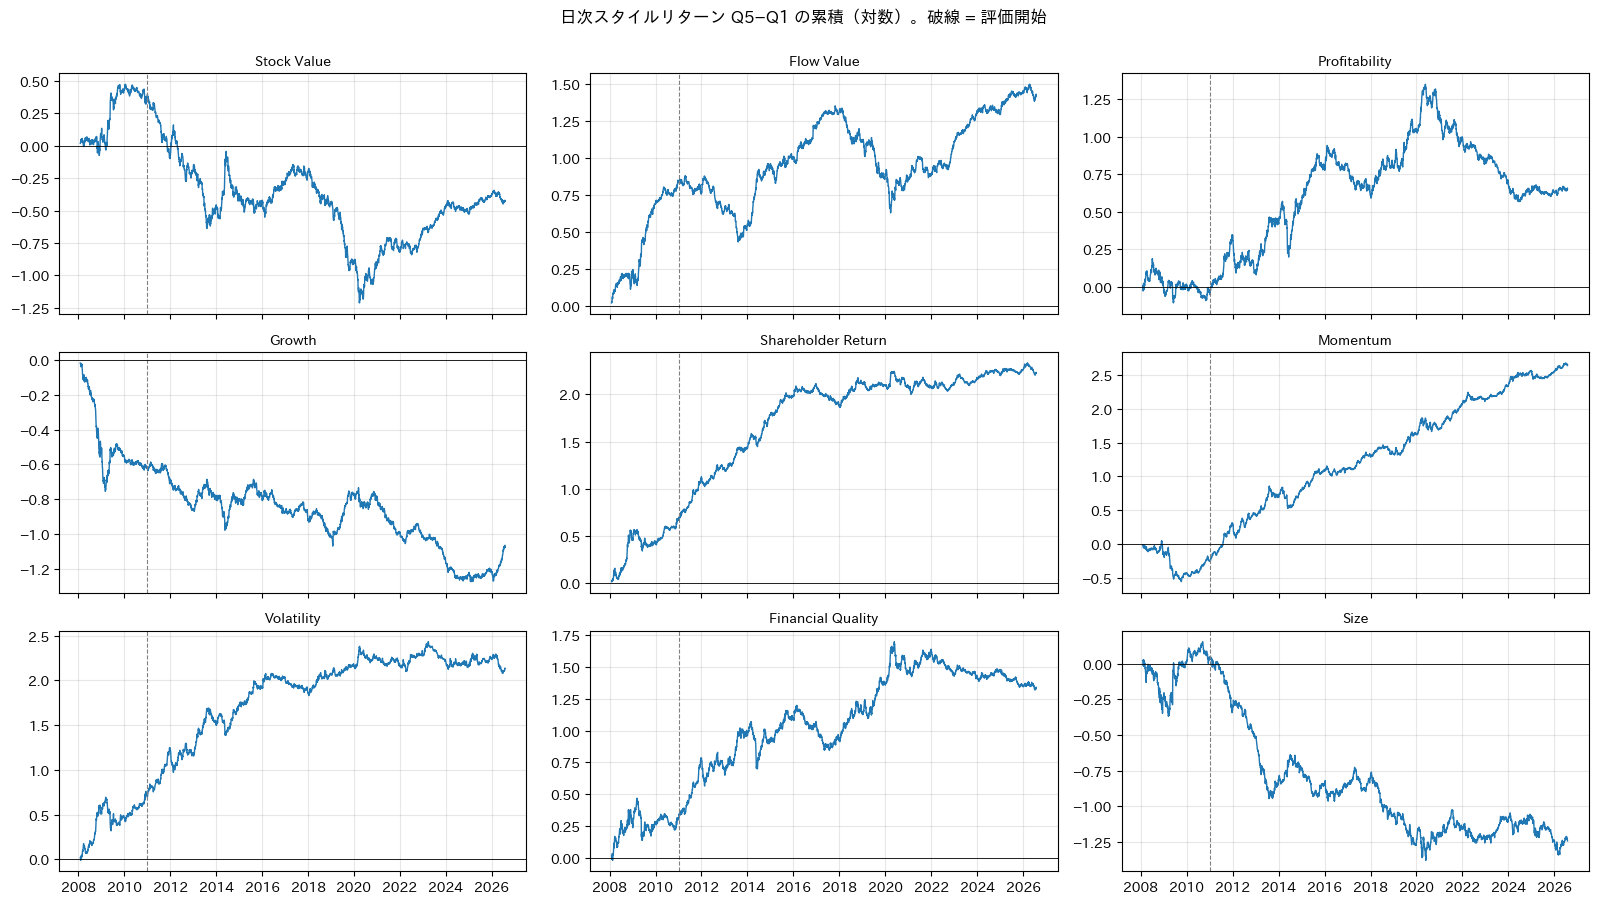

2008-02〜               2011-01〜              
                       年率平均   年率ボラ     SR     年率平均   年率ボラ     SR
Stock Value          -0.024  0.145 -0.162   -0.053  0.144 -0.370
Flow Value            0.078  0.104  0.754    0.038  0.100  0.382
Profitability         0.036  0.127  0.283    0.045  0.128  0.355
Growth               -0.059  0.087 -0.672   -0.029  0.080 -0.359
Shareholder Return    0.123  0.104  1.179    0.102  0.095  1.073
Momentum              0.146  0.126  1.155    0.189  0.122  1.547
Volatility            0.118  0.138  0.852    0.093  0.133  0.704
Financial Quality     0.074  0.132  0.557    0.068  0.123  0.551
Size                 -0.069  0.129 -0.531   -0.084  0.117 -0.721

日次スタイルリターンの相関（2008-02〜）


,Stock Value,Flow Value,Profitability,Growth,Shareholder Return,Momentum,Volatility,Financial Quality,Size
Stock Value,1.00,0.73,-0.75,-0.25,-0.52,-0.48,-0.63,-0.72,0.38
Flow Value,0.73,1.00,-0.37,-0.15,-0.17,-0.44,-0.35,-0.40,0.36
Profitability,-0.75,-0.37,1.00,0.34,0.62,0.30,0.63,0.78,-0.30
Growth,-0.25,-0.15,0.34,1.00,-0.14,0.13,0.05,-0.01,-0.04
Shareholder Return,-0.52,-0.17,0.62,-0.14,1.00,0.22,0.60,0.70,-0.22
Momentum,-0.48,-0.44,0.30,0.13,0.22,1.00,0.17,0.32,-0.26
Volatility,-0.63,-0.35,0.63,0.05,0.60,0.17,1.00,0.62,-0.50
Financial Quality,-0.72,-0.40,0.78,-0.01,0.70,0.32,0.62,1.00,-0.20
Size,0.38,0.36,-0.30,-0.04,-0.22,-0.26,-0.50,-0.20,1.00


In [3]:
G = np.log1p(g).cumsum()
fig, axes = plt.subplots(3, 3, figsize=(16, 9), sharex=True)
for ax, s in zip(axes.ravel(), STYLES):
    ax.plot(G.index, G[s], linewidth=1)
    ax.axvline(pd.Timestamp("2011-01-01"), color="gray", linestyle="--", linewidth=0.8)
    ax.axhline(0, color="k", linewidth=0.6)
    ax.set_title(s, fontsize=10)
fig.suptitle("日次スタイルリターン Q5−Q1 の累積（対数）。破線 = 評価開始", y=1.0)
plt.tight_layout()
plt.show()

lg = np.log1p(g)


def stats(x: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "年率平均": x.mean() * 252,
            "年率ボラ": x.std() * np.sqrt(252),
            "SR": x.mean() / x.std() * np.sqrt(252),
        }
    )


display(
    pd.concat(
        {"2008-02〜": stats(lg), "2011-01〜": stats(lg.loc["2011-01-01":])}, axis=1
    ).round(3)
)
print("日次スタイルリターンの相関（2008-02〜）")
display(g.corr().round(2))

## 3. スタイル単位の予測診断

個別株スコアに変換する前に、スタイルリターンの予測そのものが当たっているかを確認する。
対象は 2011-01〜2026-05 の月末（翌月の実現値がある月）× 9 スタイル。

- **符号的中率**: 予測の符号と翌月実現値の符号が一致した割合。約 1,660 サンプルなので標準誤差は約 1.2%
- **相関**: 予測と実現値の相関（全体は $\hat\sigma$ で割って比較可能にしたもの、スタイル別はスタイルごとの時系列相関の平均）

In [4]:
ev = fc[fc["month"] >= "2011-01-01"].dropna(subset=["realized"]).copy()
METHODS = {
    "dtw": "DTW",
    "dtw_z": "DTW（標準化）",
    "euclid": "ユークリッド",
    "hist": "過去平均",
    "mom12": "12か月モメンタム",
    "mom3": "3か月モメンタム",
}
rows, by_style = {}, {}
for m, label in METHODS.items():
    d = ev.dropna(subset=[m])
    by = d.groupby("style").apply(lambda x, m=m: x[m].corr(x["realized"]))
    by_style[label] = by
    rows[label] = {
        "サンプル数": len(d),
        "符号的中率": (np.sign(d[m]) == np.sign(d["realized"])).mean(),
        "相関（全体、σ 調整）": (d[m] / d["sigma"]).corr(d["realized"] / d["sigma"]),
        "相関（スタイル別の平均）": by.mean(),
        "相関 > 0 のスタイル数": int((by > 0).sum()),
    }
display(pd.DataFrame(rows).T.round(3))
print("スタイル別の時系列相関（予測 vs 翌月実現値）")
display(pd.DataFrame(by_style).round(3))

,サンプル数,符号的中率,相関（全体、σ 調整）,相関（スタイル別の平均）,相関 > 0 のスタイル数
DTW,1665.0,0.522,0.066,0.034,4.0
DTW（標準化）,1665.0,0.535,0.034,0.010,3.0
ユークリッド,1665.0,0.510,0.061,0.031,7.0
過去平均,1665.0,0.557,0.091,-0.047,3.0
12か月モメンタム,1665.0,0.548,0.094,0.034,7.0
3か月モメンタム,1665.0,0.545,0.056,0.022,5.0


スタイル別の時系列相関（予測 vs 翌月実現値）


,DTW,DTW（標準化）,ユークリッド,過去平均,12か月モメンタム,3か月モメンタム
style,,,,,,
Financial Quality,-0.013,-0.098,0.002,-0.014,-0.020,-0.074
Flow Value,-0.056,-0.023,-0.183,-0.105,0.093,0.108
Growth,0.025,0.037,0.065,0.003,0.009,0.163
Momentum,-0.011,-0.000,0.012,-0.198,-0.097,-0.059
Profitability,-0.058,-0.019,-0.005,-0.104,0.036,-0.007
Shareholder Return,0.174,0.182,0.241,0.172,0.132,0.036
Size,0.191,0.100,0.051,-0.105,0.045,0.025
Stock Value,-0.019,-0.062,0.028,-0.186,0.067,0.046
Volatility,0.070,-0.030,0.067,0.110,0.036,-0.038


### 予測の 5 分位別の翌月リターン（野村資料 p.5 と同じ形式）

スタイルごとに予測値を時系列で 5 分位に分け（grp5 = 予測が最も高い）、翌月の実現リターン（$\hat\sigma$ 単位）を平均した。
全期間の分位を使うので先読みを含む診断であり、予測の単調性を見るためのもの。

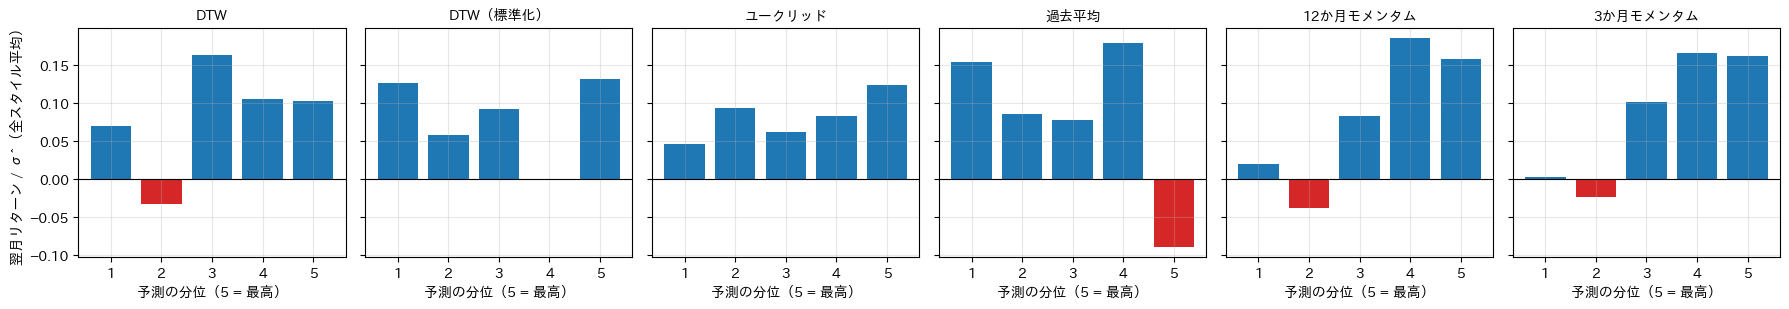

DTW: スタイル別の分位平均（翌月リターン / σ̂）


grp,1,2,3,4,5
Stock Value,-0.18,0.01,0.00,-0.04,-0.27
Flow Value,0.23,-0.11,0.32,0.11,-0.08
Profitability,0.33,-0.03,-0.15,0.25,0.05
Growth,-0.13,-0.15,0.02,-0.19,-0.01
Shareholder Return,-0.00,0.16,0.36,0.24,0.37
Momentum,0.59,0.38,0.25,0.23,0.55
Volatility,0.10,-0.24,0.31,0.46,0.12
Financial Quality,0.01,0.09,0.35,0.14,-0.01
Size,-0.30,-0.40,-0.01,-0.26,0.19


In [5]:
def quintile_means(d: pd.DataFrame, col: str) -> pd.Series:
    d = d.dropna(subset=[col]).copy()
    d["grp"] = d.groupby("style")[col].transform(
        lambda x: pd.qcut(x.rank(method="first"), 5, labels=False) + 1
    )
    return (d["realized"] / d["sigma"]).groupby(d["grp"]).mean()


qm = pd.DataFrame({label: quintile_means(ev, m) for m, label in METHODS.items()})
fig, axes = plt.subplots(1, len(METHODS), figsize=(18, 3.2), sharey=True)
for ax, label in zip(axes, qm.columns):
    ax.bar(qm.index, qm[label], color=["C3" if v < 0 else "C0" for v in qm[label]])
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("予測の分位（5 = 最高）")
axes[0].set_ylabel("翌月リターン / σ̂（全スタイル平均）")
plt.tight_layout()
plt.show()

print("DTW: スタイル別の分位平均（翌月リターン / σ̂）")
display(
    pd.DataFrame(
        {s: quintile_means(ev[ev["style"] == s], "dtw") for s in STYLES}
    ).T.round(2)
)

### 近傍の例（直近月）

最新の月末について、クエリ（直近 63 営業日、黒）と DTW で選ばれた近傍 3 つ（終端の後 21 営業日まで）を重ねた。
横軸 0 が窓の終端で、右側が予測に使う翌 21 営業日。

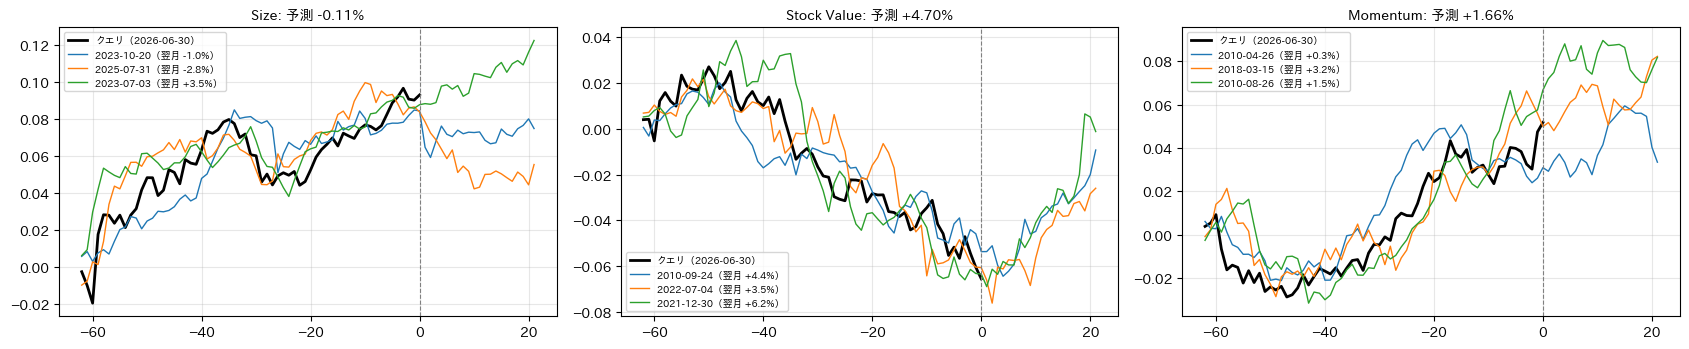

In [6]:
def path(style: str, end: pd.Timestamp, fwd: int) -> np.ndarray:
    s = G[style]
    pos = s.index.get_loc(end)
    return s.iloc[pos - WINDOW + 1 : pos + fwd + 1].to_numpy() - s.iloc[pos - WINDOW]


last = nbr["month"].max()
show = ["Size", "Stock Value", "Momentum"]
fig, axes = plt.subplots(1, len(show), figsize=(17, 3.6))
for ax, s in zip(axes, show):
    qday = g.index[g.index.to_period("M") == last.to_period("M")].max()
    q = path(s, qday, 0)
    ax.plot(
        np.arange(-WINDOW + 1, 1),
        q,
        color="k",
        linewidth=2,
        label=f"クエリ（{qday.date()}）",
    )
    sel = nbr[(nbr["style"] == s) & (nbr["method"] == "dtw") & (nbr["month"] == last)]
    for _, r in sel.iterrows():
        p = path(s, r["neighbor_end"], HORIZON)
        ax.plot(
            np.arange(-WINDOW + 1, HORIZON + 1),
            p,
            linewidth=1,
            label=f"{r['neighbor_end'].date()}（翌月 {r['forward']:+.1%}）",
        )
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    mu = fc[(fc["style"] == s) & (fc["month"] == last)]["dtw"].iloc[0]
    ax.set_title(f"{s}: 予測 {mu:+.2%}", fontsize=10)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 4. 個別株スコアの評価

各スコアを Q5（等ウェイトの BM 超過）→ IC → Q5−Q1 の順に見る。`base_ew`（全スタイル等ウェイト）との差が、
スタイルの時変ウェイト（DTW などの予測）で上乗せされた部分。回転率は年率。

In [7]:
returns = {
    kind: store.returns(RISK_MODEL, col, START, 202607)
    for kind, col in RETURN_KINDS.items()
}
reports = {
    n: compute_alpha_report(
        n,
        s,
        univ,
        bm,
        returns,
        n_quantiles=N_QUANTILES,
        cw_max_weight=CW_MAX_WEIGHT,
        burn_in=BURN_IN,
    )
    for n, s in scores.items()
}
first = next(iter(reports.values()))
ew = first.series["ew_excess"]["drtn"]
print(
    f"最上位 = {first.top}。評価期間 {ew.index.min().date()}〜{ew.index.max().date()}（{len(ew)} か月）"
)

tbl = summary_table(reports)
q5, sp = first.label("ew_excess"), first.label("spread")
cols = [q5, q5 + " IR", "IC", "ICIR", "IC t", sp, sp + " IR"]
for kind in ["drtn", "srtn"]:
    print(
        f"{kind}（{'配当込みトータルリターン' if kind == 'drtn' else '固有リターン'}）"
    )
    display(tbl[kind][cols].round(3))
display(tbl["共通"][["回転率 EW"]].round(2))

最上位 = Q5。評価期間 2011-03-31〜2026-07-31（185 か月）
drtn（配当込みトータルリターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
sdtw,0.067,0.593,0.039,0.270,3.668,0.124,0.860
sdtw_z,0.031,0.264,0.023,0.152,2.072,0.052,0.340
sdtw_sign,0.051,0.432,0.026,0.176,2.399,0.085,0.560
sdtw_pos,0.071,0.646,0.047,0.322,4.375,0.142,0.985
sknn_euc,0.064,0.545,0.036,0.229,3.114,0.121,0.778
base_ew,0.075,0.684,0.040,0.325,4.414,0.110,0.844
base_hist,0.052,0.686,0.054,0.336,4.567,0.103,0.609
base_mom12,0.062,0.537,0.037,0.183,2.493,0.083,0.405
base_mom3,0.050,0.360,0.022,0.108,1.469,0.060,0.286
comp_ew,0.124,1.111,0.063,0.482,6.557,0.184,1.267


srtn（固有リターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
sdtw,0.061,0.639,0.018,0.158,2.155,0.065,0.611
sdtw_z,0.047,0.497,0.017,0.148,2.017,0.036,0.321
sdtw_sign,0.064,0.691,0.018,0.158,2.143,0.065,0.585
sdtw_pos,0.058,0.600,0.020,0.189,2.572,0.067,0.651
sknn_euc,0.064,0.667,0.018,0.150,2.045,0.072,0.630
base_ew,0.065,0.638,0.018,0.190,2.590,0.048,0.472
base_hist,0.045,0.646,0.032,0.283,3.844,0.046,0.421
base_mom12,0.049,0.502,0.011,0.075,1.024,0.026,0.184
base_mom3,0.047,0.412,0.006,0.037,0.507,0.021,0.144
comp_ew,0.104,1.050,0.033,0.319,4.335,0.104,0.948


指標,回転率 EW
sdtw,8.03
sdtw_z,8.53
sdtw_sign,8.57
sdtw_pos,6.68
sknn_euc,8.26
base_ew,2.58
base_hist,1.96
base_mom12,3.05
base_mom3,5.18
comp_ew,4.00


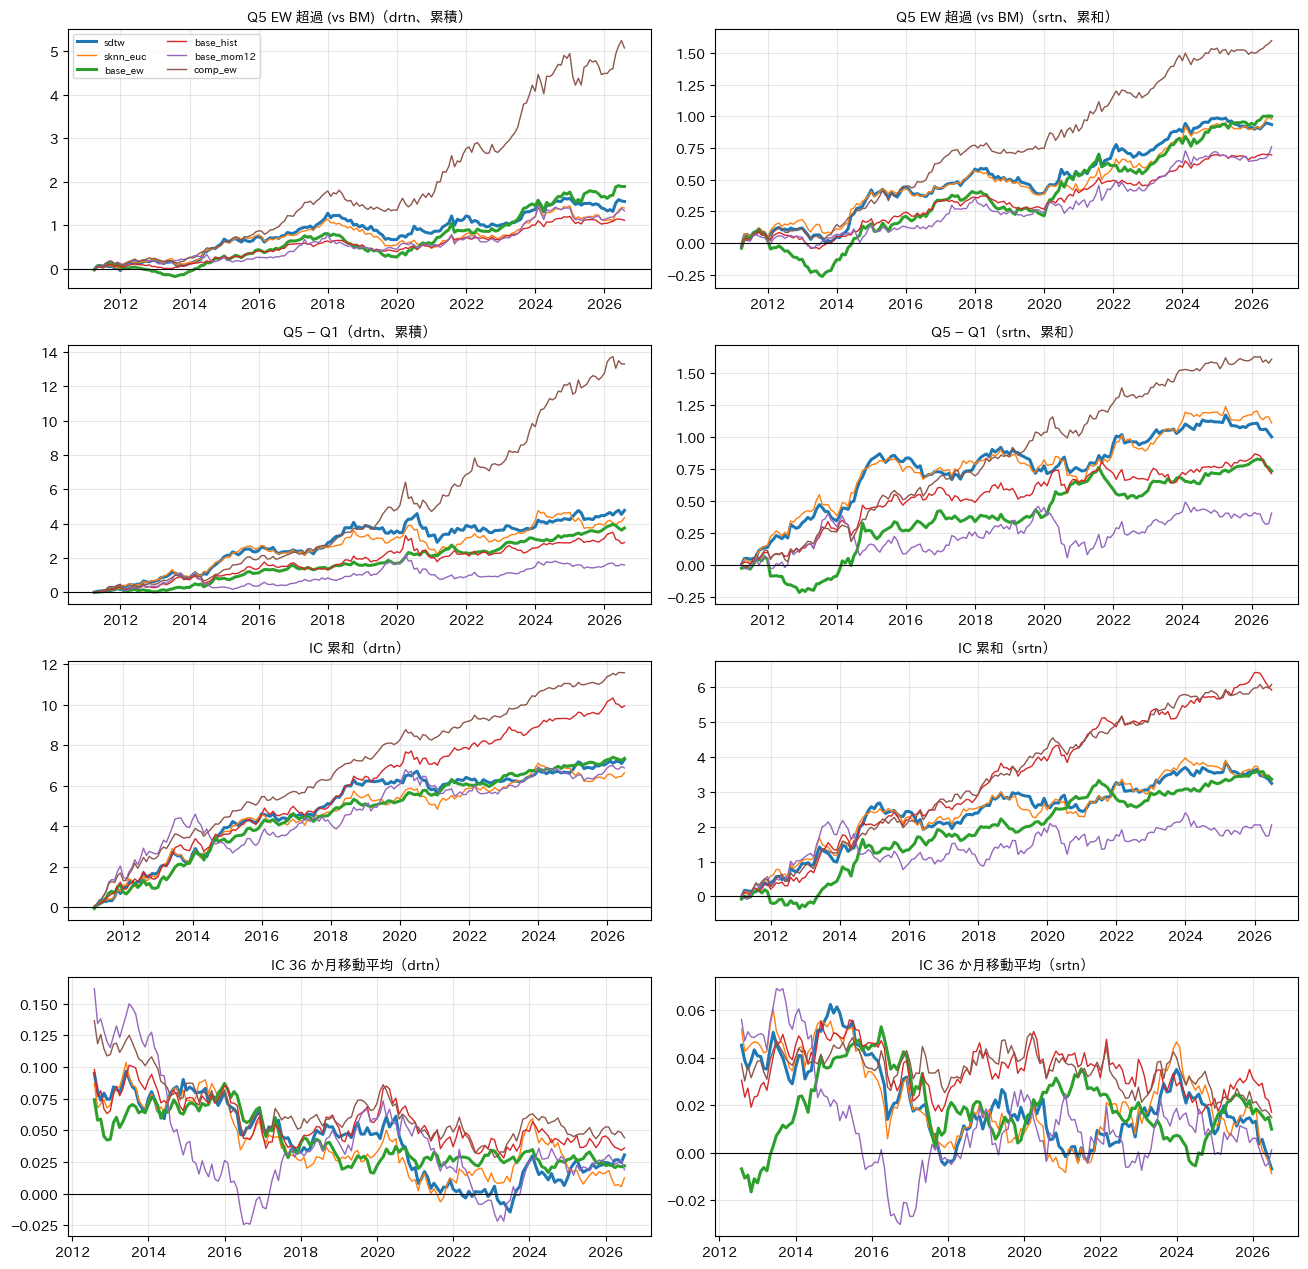

In [8]:
main = {
    n: reports[n]
    for n in ["sdtw", "sknn_euc", "base_ew", "base_hist", "base_mom12", "comp_ew"]
}
fig = plot_cumulative(
    main, metrics=("ew_excess", "ic", "spread"), highlight=("sdtw", "base_ew")
)
plt.show()

### 期間別（drtn）

Q5 の BM 超過（年率）と IC 平均を 3 期間に分けた。

In [9]:
periods = {
    "2011–2015": ("2011-01-01", "2015-12-31"),
    "2016–2019": ("2016-01-01", "2019-12-31"),
    "2020–2026": ("2020-01-01", "2026-12-31"),
}
rows = {}
for n, rep in reports.items():
    r = {}
    for p, (a, b) in periods.items():
        r[(p, "Q5 超過")] = rep.series["ew_excess"]["drtn"].loc[a:b].mean() * 12
        r[(p, "IC")] = rep.series["ic"]["drtn"].loc[a:b].mean()
    rows[n] = r
display(pd.DataFrame(rows).T.round(3))

2011–2015        2016–2019        2020–2026       
               Q5 超過     IC     Q5 超過     IC     Q5 超過     IC
sdtw           0.123  0.078    -0.005  0.033     0.070  0.014
sdtw_z         0.030  0.045    -0.046  0.020     0.079  0.009
sdtw_sign      0.099  0.061    -0.052  0.020     0.078  0.004
sdtw_pos       0.120  0.087    -0.019  0.046     0.091  0.017
sknn_euc       0.128  0.077    -0.030  0.017     0.073  0.016
base_ew        0.082  0.070    -0.027  0.024     0.132  0.027
base_hist      0.075  0.078    -0.001  0.049     0.066  0.038
base_mom12     0.054  0.061     0.039  0.052     0.080  0.010
base_mom3      0.080  0.051    -0.027  0.035     0.075 -0.009
comp_ew        0.135  0.093     0.061  0.058     0.154  0.042

### スコア間の順位相関（月次平均）

DTW スコアが、静的な等ウェイト合成やスタイルモメンタムとどれだけ違うか。

In [10]:
def row_rank_corr(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    m = a.notna() & b.notna()
    ra, rb = a.where(m).rank(axis=1), b.where(m).rank(axis=1)
    ra, rb = ra.sub(ra.mean(axis=1), axis=0), rb.sub(rb.mean(axis=1), axis=0)
    return (ra * rb).sum(axis=1) / np.sqrt((ra**2).sum(axis=1) * (rb**2).sum(axis=1))


names = [
    "sdtw",
    "sdtw_z",
    "sknn_euc",
    "base_ew",
    "base_hist",
    "base_mom12",
    "base_mom3",
    "comp_ew",
]
corr = pd.DataFrame(index=names, columns=names, dtype=float)
for i, a in enumerate(names):
    for b in names[i:]:
        v = 1.0 if a == b else float(row_rank_corr(scores[a], scores[b]).mean())
        corr.loc[a, b] = corr.loc[b, a] = v
display(corr.round(2))

,sdtw,sdtw_z,sknn_euc,base_ew,base_hist,base_mom12,base_mom3,comp_ew
sdtw,1.00,0.46,0.74,0.24,0.45,0.19,0.09,0.28
sdtw_z,0.46,1.00,0.42,0.18,0.36,0.19,0.10,0.21
sknn_euc,0.74,0.42,1.00,0.25,0.43,0.23,0.12,0.29
base_ew,0.24,0.18,0.25,1.00,0.61,0.25,0.12,0.41
base_hist,0.45,0.36,0.43,0.61,1.00,0.42,0.22,0.53
base_mom12,0.19,0.19,0.23,0.25,0.42,1.00,0.53,0.36
base_mom3,0.09,0.10,0.12,0.12,0.22,0.53,1.00,0.23
comp_ew,0.28,0.21,0.29,0.41,0.53,0.36,0.23,1.00


## 5. 所見

**結論: 現在の設定では、DTW によるスタイルの時変ウェイトは、静的な等ウェイト（`base_ew`）に上乗せがない。回転率だけが約 3 倍になる。**

1. **符号調整**: スタイル内で逆向きに効いているのは `mscore`（LOO 相関 −0.22）と `tover`（−0.07）だけだった。
   `mscore` は元データの `acc_cf`（負のアクルーアルの向き）を正の係数で含む式で作られている可能性があり、反転か除外を検討する
   （Financial Quality 28 本中 1 本なので、今回の結論への影響は小さい）。
2. **スタイル単位の予測**: DTW の符号的中率は 52.2%（50% から約 +1.8 標準誤差）、予測と実現値の相関は 0.07。
   12 か月モメンタム（54.8%、0.09）や過去平均（55.7%）より良くはない。スタイル別では Size（0.19）と Shareholder Return（0.17）で正、
   Flow Value・Profitability ではわずかに負。予測の 5 分位別リターンは単調ではなく、野村資料 p.5 のような「最上位分位だけ突出する」形も出ていない。
   ユークリッド距離の kNN とも差がなく（スコアの順位相関 0.74）、時間軸の伸縮を許す DTW の利点は見えない。
3. **個別株スコア（drtn、2011-03〜2026-07）**: `sdtw` は Q5 超過 6.7%、IC 0.039、Q5−Q1 12.4%。`base_ew`（7.5%、0.040、11.0%）とほぼ同じで、
   月次の差の t 値は Q5 超過 −0.3、IC 0.0、Q5−Q1 +0.3。最も良い `sdtw_pos` でも IC +0.007（t = 0.9）、Q5−Q1 +3.2%（t = 1.0）。
   回転率は年 8.0 倍と `base_ew`（2.6 倍）の約 3 倍で、短期売買に STCG がかかるインドでは税引後でさらに不利になる。いずれも `comp_ew`（12.4%、0.063）には遠く及ばない。
4. **期間別**: DTW の上乗せは 2011〜2015 年に集中している（Q5 超過 12.3% vs `base_ew` 8.2%）。2016〜2019 年はほぼ同じで、
   2020 年以降は下回る（7.0% vs 13.2%）。野村資料でもサイズの DTW 戦略は 2012 年頃から頭打ちで、初期にだけ効いた点が似ている。

**次に試すなら**（パラメータを探るほどデータマイニングの危険が増える点に注意）

- 予測が効いているように見える Size・Shareholder Return だけに DTW を使い、他は静的ウェイトにする
- 予測が極端なときだけウェイトを傾ける（野村の「grp5 だけ効く」に対応）。回転率も抑えられる
- `mscore` の符号を見直したうえで、窓の長さ $L$（63 → 126）や近傍数 $K$（3 → 5）への感度を確認する
